# BQ2 Track B: F3-Z1 first modelling pass

July–August 2018 reference versus July–August 2019 observations. Scope stays at **F3-Z1**; no other zones are modelled.

## tl;dr

**This first pass does not establish AC decline.** Under conditions represented in the 2018 reference:

| 2019 departure from reference | With existing fills | Without filled/replaced readings |
|---|---:|---:|
| Daily AC electricity | −9.0% (25 supported days) | −10.2% (12 supported days) |
| Recorded indoor humidity ratio | −0.40 g/kg (34 hours, 18 days) | −0.41 g/kg (15 hours, 10 days) |
| Adjusted cooling-rate comparison | Inconclusive: 1 supported event | Inconclusive: 0 supported events |

The energy and moisture directions persist when filled readings are excluded. Cooler 2019 room conditions prevent a fair cooling-response comparison. Lower electricity does not establish higher efficiency, and recorded moisture can change with operation or sensor behaviour. Read the intervals and sample restrictions below before generalising beyond these cohorts.


## Context & Methods

This first pass asks whether energy, cooling response and recorded indoor moisture differ from a 2018 reference. It estimates observational departures, not causal efficiency changes or confirmed faults.

### Analysis definitions and reporting rules

- **With fills:** the existing cleaned inputs, with their existing short-gap interpolation. **Without fills:** source readings that are present and unchanged by upstream cleaning; no new filling, missing-day scaling or gap bridging.
- Only July–August in the two requested years and existing `working day` labels are used. These labels indicate inferred activity, not measured occupancy.
- Energy uses complete **1,440-minute AC-plus-plug days**. AC kWh is summed kW/60. Weather predictors are full-day means; plug kWh is an activity proxy.
- AC-on threshold: the shared formula applied once to **raw-observed July–August 2018** AC totals, then frozen for both years and variants. This avoids a threshold derived from 2019. Events require continuous 30-minute states and a sustained 60-minute post-start window. Morning starts are 06:00–09:59 and lunch restarts 12:00–14:59.
- Cooling rate is minus the OLS slope of temperature against elapsed minutes over 60 samples, multiplied by 60 (°C/hour). The reference controls for initial temperature (first-five-minute median), outdoor temperature and morning/lunch session.
- Moisture uses complete paired temperature/RH hours, a valid plug channel and at least **120 continuous AC-on minutes** ending with that hour. This excludes the first hour after a start. Mean indoor humidity ratio is modelled against outdoor humidity ratio, outdoor temperature, plug activity and session. Outdoor-minus-indoor humidity ratio remains a proxy, not coil removal rate.
- All reference coefficients use **2018 only**. Energy temperature/enthalpy specifications are compared by expanding, date-separated 2018 validation; mean-only and activity-only models are benchmarks. Energy selection never uses 2019 outcomes. Cooling/moisture specifications are fixed.
- Each reference day has equal total weight, so multiple events/hours on one day do not count as independent days. Means also balance days.
- Additional checks compare temperature/enthalpy energy specifications on the same jointly supported days and inspect moisture separately by clock hour. These do not retune the primary model or provide new causal estimates. The moisture model controls session, rather than exact clock hour or elapsed run time.
- Headline estimates require 2019 predictors inside the 2018 **convex hull**, separately by session, plus at least **10 evaluation days and four calendar weeks** in each year. This is a conservative reporting rule for this pass, not a scientific standard. Other predictions are explicitly exploratory extrapolations.
- Intervals resample calendar weeks independently within each year, refit the selected 2018 model, and use 2,000 deterministic bootstrap replicates. They are 95% conditional intervals for the observed cohorts/specification, not causal, failure-risk or future prediction intervals.
- `with/without fills` changes cohort membership as well as preprocessing. Shared-observation checks and a same-window observed-points slope diagnostic distinguish these effects. The latter requires at least 48 of 60 source temperatures spanning at least 50 minutes; it is an interpolation check, not the strict observed-only model.

### Remaining limitations

Clock alignment is assumed to be Bangkok local time; timestamps do not independently confirm it. Setpoints, maintenance, occupancy, airflow, sensor calibration and surface measurements are unavailable. The 2018 reference is not known to be fault-free. Changes in operation, load or sensor behaviour can explain observed departures.

In [1]:
from pathlib import Path
import json
import sys
import hashlib
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline
RUN_CHECKS = False
%run -i ./bq2_utils.ipynb

import f3z1_audit as audit
import f3z1_first_pass as first_pass
repo_root = Path.cwd().parent
sys.path.insert(0, str(repo_root / "baseline"))
from humidity_risk_baseline import load_bangkok_era5_weather
output_dir = Path("outputs/f3z1-first-pass")
output_dir.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 120, "savefig.dpi": 180, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 12)

## Data

### 1. Build the two input versions

Reuse the audited sources and shared psychrometric definitions. Inputs outside the two requested windows are masked before event and feature construction.

In [2]:
raw, clean, hourly, quality, removed, timeline, manifest = audit.load_inputs(repo_root)
weather = load_bangkok_era5_weather(repo_root / "baseline/data/bangkok_era5_hourly_2018-2019.csv")
helpers = {"add_outdoor_psychrometrics": add_outdoor_psychrometrics,
           "humidity_ratio_gkg": humidity_ratio_gkg, "ac_on_threshold": ac_on_threshold}
daily, events, humidity, eligibility, threshold = first_pass.build_tables(raw, clean, hourly, weather, helpers)
counts = []
for name, table in [("Energy days", daily[daily.eligible]), ("Start-up windows", events), ("Steady-on hours", humidity)]:
    for (variant, year), part in table.groupby(["variant", "year"]):
        counts.append({"analysis_unit": name, "variant": variant, "year": year,
                       "rows": len(part), "distinct_days": part.date.nunique()})
cohort_counts = pd.DataFrame(counts)
display(cohort_counts)
print(f"Frozen 2018 AC-on threshold: {threshold:.3f} kW (audit's earlier full-period value was 5.750 kW).")
for table in [daily[daily.eligible], events, humidity]:
    assert table.time.dt.year.isin([2018, 2019]).all()
    assert table.time.dt.month.isin([7, 8]).all()

,analysis_unit,variant,year,rows,distinct_days
0,Energy days,with_fills,2018,41,41
1,Energy days,with_fills,2019,40,40
2,Energy days,without_fills,2018,41,41
3,Energy days,without_fills,2019,16,16
4,Start-up windows,with_fills,2018,81,41
5,Start-up windows,with_fills,2019,78,41
6,Start-up windows,without_fills,2018,29,25
7,Start-up windows,without_fills,2019,71,41
8,Steady-on hours,with_fills,2018,142,42
9,Steady-on hours,with_fills,2019,105,38


Frozen 2018 AC-on threshold: 5.792 kW (audit's earlier full-period value was 5.750 kW).


## Results

### 2. Select the energy reference and validate the fixed models

The weather model is chosen by 2018-only validation MAE. Both benchmark errors remain visible. No model is tuned on 2019 outcomes.

In [3]:
results = first_pass.run_models(daily, events, humidity, repetitions=2000)
summary = results["summary"]
predictions = results["predictions"]
display(results["energy_candidates"].round(3))
print("Selected weather specification:", results["selected_energy_model"])
assert pd.to_datetime(results["cross_validation"].time).dt.year.eq(2018).all()
assert (pd.to_datetime(results["cross_validation"].train_last_date) <
        pd.to_datetime(results["cross_validation"].date)).all()
cv_display = summary[summary.evaluation.eq("within_reference_support")][[
    "analysis", "variant", "reference_rows", "reference_days", "reference_CV_MAE", "reference_CV_RMSE", "reference_CV_bias"]]
display(cv_display.round(4))

,candidate,predictors,MAE,RMSE,bias,validation_rows,validation_days
2,temperature_activity,"outdoor_temp_C, plug_kWh",8.890,10.898,-1.389,21,21
3,enthalpy_activity,"outdoor_enthalpy_kJkg, plug_kWh",9.384,11.422,-3.435,21,21
0,mean_only,,9.618,11.872,-2.869,21,21
1,activity_only,plug_kWh,9.988,12.155,-3.209,21,21


Selected weather specification: temperature_activity


,analysis,variant,reference_rows,reference_days,reference_CV_MAE,reference_CV_RMSE,reference_CV_bias
1,energy,with_fills,41,41,8.8896,10.8977,-1.3894
3,energy,without_fills,41,41,8.8896,10.8977,-1.3894
5,cooling,with_fills,81,41,0.3519,0.4114,0.0821
7,cooling,without_fills,29,25,0.3499,0.4149,0.0159
9,moisture,with_fills,142,42,0.1539,0.2011,-0.0205
11,moisture,without_fills,51,33,0.1884,0.2463,-0.0135


### 3. Comparable conditions and supported departures

A smaller unfilled reference can leave more 2019 conditions outside its observed range. The 2019 support check uses predictor geometry, never 2019 outcomes. Cooling results with insufficient overlap are withheld.

In [4]:
supported = summary[summary.evaluation.eq("within_reference_support")].copy()
display(supported[["analysis", "variant", "evaluation_rows", "evaluation_days", "all_eligible_2019_rows",
                   "reference_weeks", "supported_evaluation_weeks", "assessment_status"]])
display(supported[["analysis", "variant", "mean_residual", "residual_pct", "bootstrap_low", "bootstrap_high",
                   "bootstrap_percent_low", "bootstrap_percent_high", "reportable"]].round(4))

,analysis,variant,evaluation_rows,evaluation_days,all_eligible_2019_rows,reference_weeks,supported_evaluation_weeks,assessment_status
1,energy,with_fills,25,25,40,9,8,supported descriptive comparison
3,energy,without_fills,12,12,16,9,7,supported descriptive comparison
5,cooling,with_fills,1,1,78,9,1,insufficient supported days/weeks
7,cooling,without_fills,0,0,71,9,0,insufficient supported days/weeks
9,moisture,with_fills,34,18,105,9,7,supported descriptive comparison
11,moisture,without_fills,15,10,91,9,6,supported descriptive comparison


,analysis,variant,mean_residual,residual_pct,bootstrap_low,bootstrap_high,bootstrap_percent_low,bootstrap_percent_high,reportable
1,energy,with_fills,-15.7486,-9.0217,-20.8064,-9.5452,-11.8419,-5.4416,True
3,energy,without_fills,-17.8849,-10.2224,-22.8629,-11.6486,-12.9867,-6.6828,True
5,cooling,with_fills,NaN,NaN,NaN,NaN,NaN,NaN,False
7,cooling,without_fills,NaN,NaN,NaN,NaN,NaN,NaN,False
9,moisture,with_fills,-0.3962,-3.9552,-0.5858,-0.2603,-5.8497,-2.6044,True
11,moisture,without_fills,-0.4067,-4.0653,-0.6168,-0.1864,-6.1586,-1.8775,True


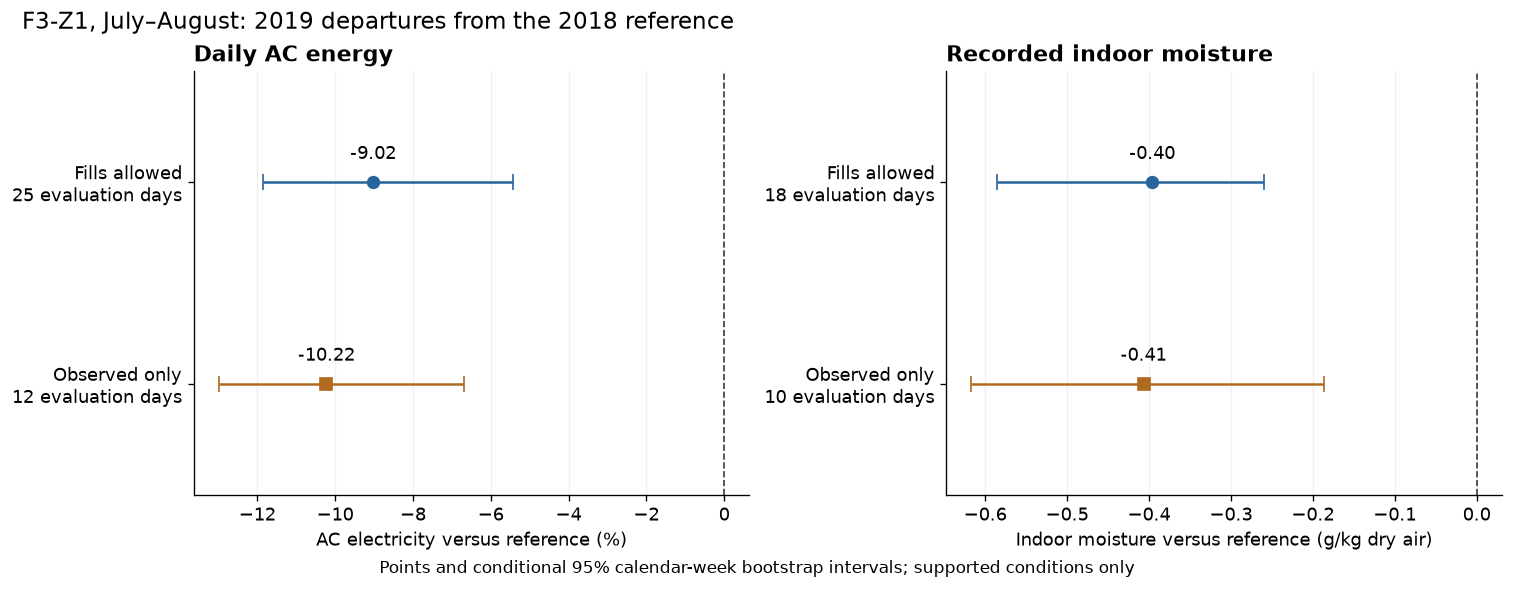

95% calendar-week bootstrap intervals; selected models and supported cohorts held fixed. These are observational departures.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), layout="constrained")
settings = [("energy", "residual_pct", "bootstrap_percent_low", "bootstrap_percent_high", "AC electricity versus reference (%)"),
            ("moisture", "mean_residual", "bootstrap_low", "bootstrap_high", "Indoor moisture versus reference (g/kg dry air)")]
colors = {"with_fills": "#27649c", "without_fills": "#b06b21"}
for ax, (analysis, point, low, high, xlabel) in zip(axes, settings):
    part = supported[(supported.analysis == analysis) & supported.reportable].set_index("variant")
    labels = []
    for y, variant in enumerate(first_pass.VARIANTS):
        row = part.loc[variant]
        ax.errorbar(row[point], y, xerr=[[row[point] - row[low]], [row[high] - row[point]]],
                    fmt="o" if variant == "with_fills" else "s", color=colors[variant], capsize=5, markersize=7)
        ax.annotate(f"{row[point]:+.2f}", (row[point], y), xytext=(0, 14), textcoords="offset points", ha="center")
        labels.append(("Fills allowed" if variant == "with_fills" else "Observed only") + f"\n{int(row.evaluation_days)} evaluation days")
    ax.axvline(0, color="#343b43", linestyle="--", linewidth=1)
    ax.set_yticks([0, 1], labels)
    ax.set_ylim(-.55, 1.55)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    ax.set_title("Daily AC energy" if analysis == "energy" else "Recorded indoor moisture", loc="left")
    ax.grid(axis="x", alpha=.18)
    ax.set_axisbelow(True)
fig.suptitle("F3-Z1, July–August: 2019 departures from the 2018 reference", x=.01, ha="left", fontsize=14)
fig.supxlabel("Points and conditional 95% calendar-week bootstrap intervals; supported conditions only", fontsize=10)
fig.savefig(output_dir / "supported_comparison.png", bbox_inches="tight")
plt.show()
print("95% calendar-week bootstrap intervals; selected models and supported cohorts held fixed. These are observational departures.")

### 4. Why cooling decline cannot be established

Compare initial conditions before interpreting the unadjusted cooling rate. Starting with a cooler room changes the amount and trajectory of cooling needed.

size    min  median    max
variant       year afternoon                            
with_fills    2018 0            41  27.31  28.220  29.74
                   1            40  26.25  28.190  28.82
              2019 0            41  24.62  25.600  27.49
                   1            37  24.23  25.820  26.72
without_fills 2018 0            13  27.31  28.190  29.44
                   1            16  26.25  28.275  28.82
              2019 0            35  24.62  25.720  27.49
                   1            36  24.23  25.785  26.72

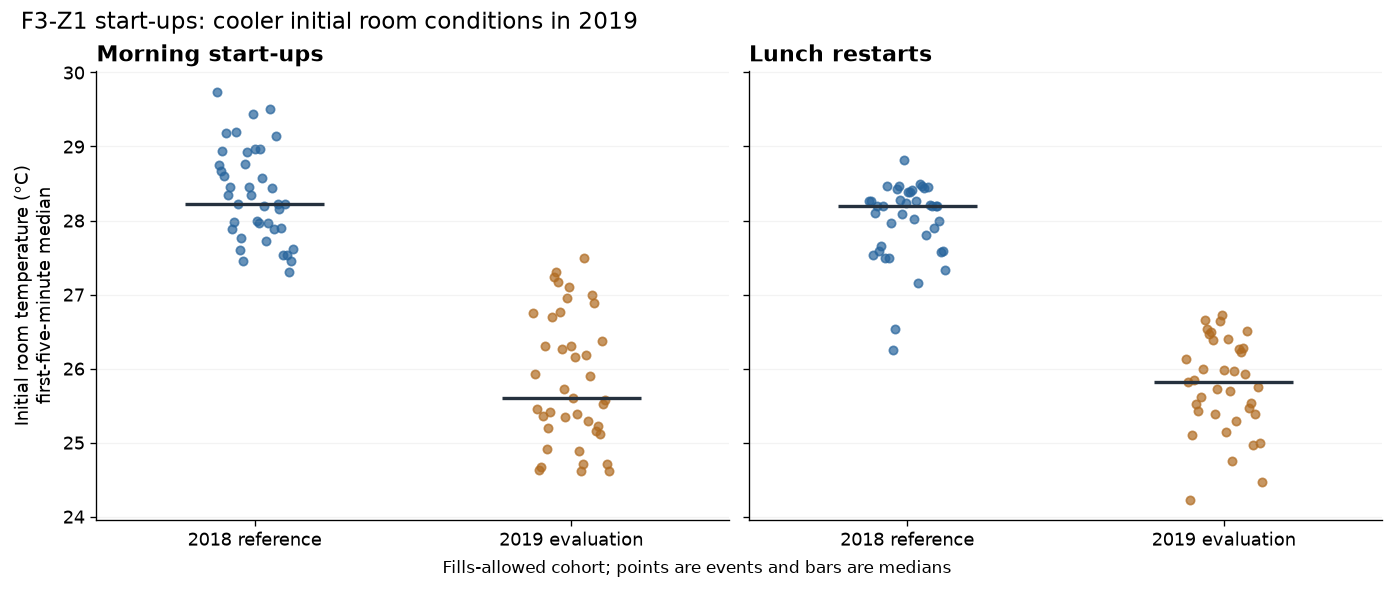

In [6]:
initial_conditions = events.groupby(["variant", "year", "afternoon"]).initial_temp_C.agg(["size", "min", "median", "max"])
display(initial_conditions.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), sharey=True, layout="constrained")
for ax, session, title in zip(axes, [0, 1], ["Morning start-ups", "Lunch restarts"]):
    for year, x, color in [(2018, 0, "#27649c"), (2019, 1, "#b06b21")]:
        values = events[(events.variant == "with_fills") & (events.year == year) & (events.afternoon == session)].initial_temp_C
        jitter = np.linspace(-.12, .12, len(values))
        ax.scatter(np.full(len(values), x) + jitter, values, alpha=.7, s=25, color=color)
        ax.hlines(values.median(), x - .22, x + .22, color="#25313e", linewidth=2)
    ax.set_xticks([0, 1], ["2018 reference", "2019 evaluation"])
    ax.set_title(title, loc="left")
    ax.set_xlim(-.5, 1.5)
    ax.grid(axis="y", alpha=.15)
axes[0].set_ylabel("Initial room temperature (°C)\nfirst-five-minute median")
fig.suptitle("F3-Z1 start-ups: cooler initial room conditions in 2019", x=.01, ha="left", fontsize=14)
fig.supxlabel("Fills-allowed cohort; points are events and bars are medians", fontsize=10)
fig.savefig(output_dir / "startup_initial_conditions.png", bbox_inches="tight")
plt.show()

### 5. Interpolation versus cohort selection

First verify that retained unfilled observations have identical model inputs and targets in both data versions. Then compare slopes on the same cleaned-eligible windows, using only observed temperature points where sufficient points remain. This diagnostic does not replace the primary continuous observed-only cohort.

In [7]:
display(results["shared_cohort_checks"])
fixed_window = first_pass.fixed_window_interpolation_check(raw, clean, events)
fixed_window_summary = fixed_window.groupby("year").agg(
    compared_windows=("time", "size"),
    median_abs_slope_difference=("clean_minus_observed_points_C_per_h", lambda x: x.abs().median()),
    max_abs_slope_difference=("clean_minus_observed_points_C_per_h", lambda x: x.abs().max()),
)
display(fixed_window_summary.round(5))
assert results["shared_cohort_checks"].max_absolute_input_or_target_difference.max() < 1e-9

,analysis,shared_rows,max_absolute_input_or_target_difference
0,energy,57,0.0
1,cooling,100,0.0
2,moisture,142,0.0


,compared_windows,median_abs_slope_difference,max_abs_slope_difference
year,,,
2018,80,0.01599,0.75658
2019,78,0.00000,0.00183


### 6. Recorded conditions and operating context

These descriptive means use all eligible observations in each version, not identical matched cohorts. RH depends on temperature; humidity ratio helps distinguish a higher RH reading from more water in the air. Neither is a direct coil moisture-removal measurement.

In [8]:
recorded_conditions = humidity.groupby(["variant", "year"])[["temp_C", "rh_pct", "indoor_w_gkg", "humidity_gap_gkg"]].mean()
operating_context = daily[daily.eligible].groupby(["variant", "year"])[["ac_kWh", "plug_kWh", "AC_on_hours", "on_mean_kW"]].mean()
display(recorded_conditions.round(3))
display(operating_context.round(3))
# Exploratory CUSUM is recorded per cohort, over available eligible days only.
# Its totals cannot be compared directly when cohort sizes differ, and no fault threshold is fitted.
cusum = predictions[predictions.analysis.eq("energy")][["variant", "time", "actual", "prediction", "residual", "within_reference_support", "cusum_observed_rows"]]
display(cusum.groupby("variant").agg(available_days=("time", "size"), cumulative_residual_kWh=("residual", "sum")).round(3))

temp_C  rh_pct  indoor_w_gkg  humidity_gap_gkg
variant       year                                                
with_fills    2018  24.269  52.932         9.987             9.149
              2019  22.098  57.424         9.496             9.458
without_fills 2018  24.200  52.893         9.938             9.166
              2019  22.083  57.426         9.487             9.543

ac_kWh  plug_kWh  AC_on_hours  on_mean_kW
variant       year                                            
with_fills    2018  174.400     8.447        7.239      23.890
              2019  164.571     8.035        7.015      23.143
without_fills 2018  174.400     8.447        7.239      23.890
              2019  163.537     8.065        7.069      22.928

,available_days,cumulative_residual_kWh
variant,,
with_fills,40,-476.843
without_fills,16,-219.387


### 7. Bounded specification and clock-hour checks

Both weather specifications are evaluated on their common supported days, so a changed cohort does not explain their difference. The selected model remains the 2018 validation winner. Clock-hour moisture means are descriptive and use all eligible hours; they show whether session composition alone reverses the direction, without claiming weather or activity matching.


In [9]:
energy_specification_check, moisture_clock_hour_check = first_pass.specification_checks(daily, humidity)
display(energy_specification_check.round(3))
display(moisture_clock_hour_check.round(3))


,variant,specification,common_supported_days,observed_mean_kWh,expected_mean_kWh,residual_pct
0,with_fills,temperature_activity,22,158.122,174.451,-9.360
1,with_fills,enthalpy_activity,22,158.122,176.122,-10.220
2,without_fills,temperature_activity,11,156.636,175.248,-10.620
3,without_fills,enthalpy_activity,11,156.636,176.387,-11.198


,variant,year,hour,size,mean
0,with_fills,2018,9,41,10.108
1,with_fills,2018,10,41,9.918
2,with_fills,2018,14,18,10.065
3,with_fills,2018,15,42,9.904
4,with_fills,2019,9,38,9.627
5,with_fills,2019,10,36,9.446
6,with_fills,2019,15,31,9.394
7,without_fills,2018,9,14,10.096
8,without_fills,2018,10,12,9.938
9,without_fills,2018,14,6,9.942


## Takeaways

- **Energy:** supported daily use is 9.0% below the 2018 reference with fills (conditional 95% interval: −11.8% to −5.4%) and 10.2% below without fills (−13.0% to −6.7%). The temperature-plus-activity model has 2018 validation MAE 8.89 kWh/day versus 9.62 for a mean-only reference, a modest improvement. Its inputs describe weather/activity, not delivered cooling. On the same days supported by both weather specifications, temperature and enthalpy give similarly negative departures.
- **Recorded moisture:** supported indoor humidity ratio is lower by 0.40 g/kg with fills (−0.59 to −0.26) and 0.41 g/kg without (−0.62 to −0.19). Across all eligible fills-allowed steady-on hours, RH rises from 52.9% to 57.4%, while room temperature falls from 24.3°C to 22.1°C and humidity ratio falls from 9.99 to 9.50 g/kg. Those descriptive means use different cohorts. The common clock hours also show lower 2019 absolute moisture, but are not weather-matched estimates.
- **Cooling:** the average initial room temperature is about 28.2°C in 2018 versus 25.8°C in 2019. Only 1/78 fills-allowed and 0/71 observed-only evaluation events lie within the reference conditions. Withhold an adjusted rate comparison. Slower unadjusted cooling does not establish decline when the starting rooms differ this much.
- **Filling sensitivity:** 2019 complete energy days fall from 40 to 16; 2018 cooling events fall from 81 to 29. Retained observed inputs and targets agree exactly between variants. On the same eligible event windows, the median absolute slope difference from using observed temperature points alone is 0.016°C/hour in 2018 and essentially zero in 2019, although one 2018 difference reaches 0.757°C/hour. Interpolation is usually a small numerical change in that diagnostic, but affects sample selection substantially and can matter for individual events.
- **Limits:** supported moisture evidence is sparse (18/10 evaluation days). The bootstrap intervals are conditional on the chosen models and cohorts, with only 6–8 evaluation weeks. Clock alignment, sensor calibration, setpoints and operations remain unresolved. Lower electrical input does not establish higher efficiency, and lower room-air humidity ratio does not establish improved coil removal or lower surface mould risk.
- **Review boundary:** no other zones have been modelled. This pass supports revisiting the original RH-rise hypothesis; it does not identify a mechanical fault, a control change or a sensor offset. Review these findings before expanding the analysis.


### Save reproducible evidence

All output stays in this first pass's own folder. Source data and the shared helper are checked for unchanged hashes. Previous audit outputs are preserved.

In [10]:
tables = {"daily_features": daily, "event_features": events, "steady_on_features": humidity,
          "event_eligibility": eligibility, "cohort_counts": cohort_counts,
          "energy_specification_check": energy_specification_check,
          "moisture_clock_hour_check": moisture_clock_hour_check,
          "fixed_window_interpolation": fixed_window,
          "fixed_window_summary": fixed_window_summary.reset_index(),
          "recorded_conditions": recorded_conditions.reset_index(),
          "operating_context": operating_context.reset_index(), "cusum_available_days": cusum}
for name, value in results.items():
    if isinstance(value, pd.DataFrame): tables[name] = value
for name, table in tables.items(): table.to_csv(output_dir / f"{name}.csv", index=False)
report = {"scope": "F3-Z1 only; July-August 2018 reference and July-August 2019 evaluation",
          "frozen_AC_on_threshold_kW": threshold, "selected_energy_model": results["selected_energy_model"],
          "specifications": results["specifications"], "bootstrap_replicates": 2000,
          "reporting_gate": "At least 10 supported evaluation days and four reference/evaluation calendar weeks",
          "results": json.loads(summary.to_json(orient="records")),
          "versions": {p: metadata.version(p) for p in ["pandas", "numpy", "statsmodels", "scipy", "matplotlib"]},
          "input_manifest": manifest,
          "model_code_sha256": hashlib.sha256(Path("f3z1_first_pass.py").read_bytes()).hexdigest()}
(output_dir / "summary.json").write_text(json.dumps(report, indent=2) + "\n")
for item in manifest:
    assert hashlib.sha256((repo_root / item["path"]).read_bytes()).hexdigest() == item["sha256"]
print("Saved first-pass results. Source hashes unchanged; no other zones modelled.")

Saved first-pass results. Source hashes unchanged; no other zones modelled.
